In [2]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp311-cp311-macosx_12_0_arm64.whl.metadata (4.4 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-1-py2.py3-none-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp311-cp311-macosx_10_9_

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print(tf.__version__)

2.21.0


In [30]:
dataset = pd.read_csv('/Users/yadavraunak50gmail.com/myenv/Deep Learning/Churn_Modelling (1).csv')

In [31]:
dataset

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [33]:
dataset.head()
# print(df.shape)
# print(df.info())
# print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [34]:
dataset.shape

(10000, 14)

In [35]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [36]:
dataset.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [37]:
dataset.drop(
    columns=["CustomerId", "Surname"],
    inplace=True
)

/var/folders/lf/0p15d9fx0jjgnppgskwzkqz00000gn/T/ipykernel_10959/2665218986.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dataset.drop(


In [38]:
X = dataset.drop("Exited", axis=1)

y = dataset["Exited"]

In [39]:
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True,
    dtype=int
)

print(X.head())

   RowNumber  CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          1          619   42       2       0.00              1          1   
1          2          608   41       1   83807.86              1          0   
2          3          502   42       8  159660.80              3          1   
3          4          699   39       1       0.00              2          0   
4          5          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88                  0                0   
1               1        112542.58                  0                1   
2               0        113931.57                  0                0   
3               0         93826.63                  0                0   
4               1         79084.10                  0                1   

   Gender_Male  
0            0  
1            0  
2            0  
3           

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 12)
Testing data: (2000, 12)


In [41]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [42]:
x = tf.constant([-2.0, -1.0, 0.0, 1.0, 2.0])

# 1. Sigmoid
print("Sigmoid:")
print(tf.keras.activations.sigmoid(x))

# 2. Tanh
print("Tanh:")
print(tf.keras.activations.tanh(x))

# 3. ReLU
print("ReLU:")
print(tf.keras.activations.relu(x))

# 4. Leaky ReLU
print("Leaky ReLU:")
print(tf.keras.layers.LeakyReLU(
    negative_slope=0.01
)(x))

# 5. Softmax
print("Softmax:")
print(tf.keras.activations.softmax(x))

# 6. GELU
print("GELU:")
print(tf.keras.activations.gelu(x))

Sigmoid:
tf.Tensor([0.11920294 0.2689414  0.5        0.73105854 0.8807971 ], shape=(5,), dtype=float32)
Tanh:
tf.Tensor([-0.9640276 -0.7615942  0.         0.7615942  0.9640276], shape=(5,), dtype=float32)
ReLU:
tf.Tensor([0. 0. 0. 1. 2.], shape=(5,), dtype=float32)
Leaky ReLU:
tf.Tensor([-0.02 -0.01  0.    1.    2.  ], shape=(5,), dtype=float32)
Softmax:
tf.Tensor([0.01165623 0.03168492 0.08612854 0.23412165 0.6364086 ], shape=(5,), dtype=float32)
GELU:
tf.Tensor([-0.04550027 -0.15865526  0.          0.8413448   1.9544997 ], shape=(5,), dtype=float32)


In [43]:
model = tf.keras.Sequential()

# Input layer
model.add(
    tf.keras.layers.Input(shape=(X_train.shape[1],))
)

# Hidden layer 1
model.add(
    tf.keras.layers.Dense(
        64,
        activation="relu"
    )
)

# Dropout
model.add(
    tf.keras.layers.Dropout(0.3)
)

# Hidden layer 2
model.add(
    tf.keras.layers.Dense(32)
)

# Leaky ReLU activation
model.add(
    tf.keras.layers.LeakyReLU(negative_slope=0.01)
)

# Output layer
model.add(
    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [45]:
predictions = model.predict(X_train[:5])

print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
[[0.57633054]
 [0.50706077]
 [0.4844839 ]
 [0.5269358 ]
 [0.4322286 ]]


In [46]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/50


200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7872 - loss: 0.4827 - val_accuracy: 0.8175 - val_loss: 0.4241
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 853us/step - accuracy: 0.8144 - loss: 0.4271 - val_accuracy: 0.8375 - val_loss: 0.4060
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 849us/step - accuracy: 0.8259 - loss: 0.4095 - val_accuracy: 0.8506 - val_loss: 0.3836
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 831us/step - accuracy: 0.8347 - loss: 0.3911 - val_accuracy: 0.8606 - val_loss: 0.3629
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - accuracy: 0.8423 - loss: 0.3809 - val_accuracy: 0.8662 - val_loss: 0.3507
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 922us/step - accuracy: 0.8455 - loss: 0.3736 - val_accuracy: 0.8700 - val_loss: 0.3423
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step - accuracy: 0.8516 - loss: 0.3650 - val_accuracy: 0.8731 - val_loss: 0.3377
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step - accuracy: 0.8502 - loss: 0.3642 - val_accuracy:

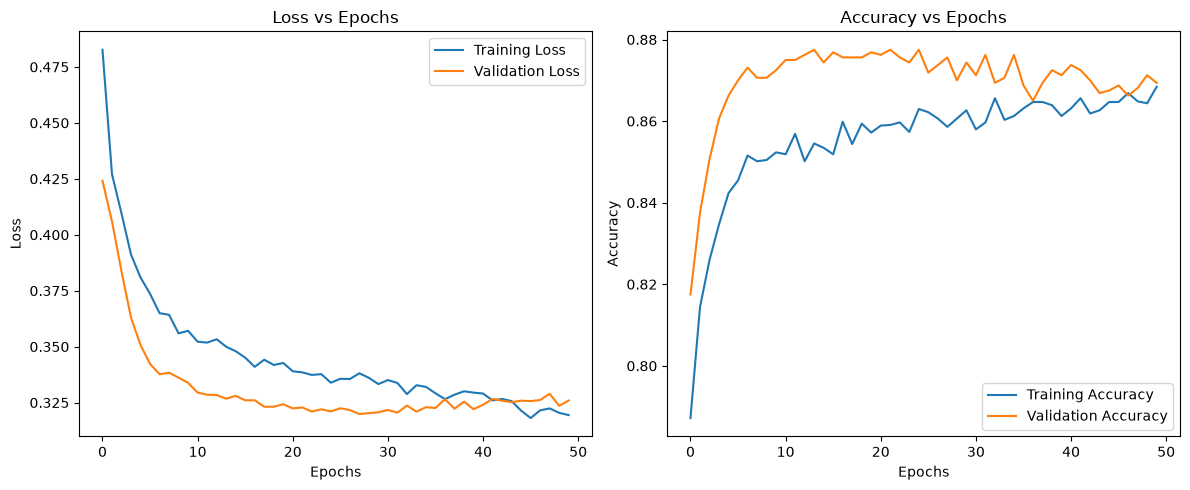

In [47]:
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Accuracy vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [48]:
y_pred = model.predict(X_test)

# Convert probabilities into 0 or 1
y_pred = (y_pred >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 513us/step
Accuracy: 0.865

Confusion Matrix:
[[1533   60]
 [ 210  197]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.77      0.48      0.59       407

    accuracy                           0.86      2000
   macro avg       0.82      0.72      0.76      2000
weighted avg       0.86      0.86      0.85      2000



In [49]:
model.save("churn_ann_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [50]:
loaded_model = tf.keras.models.load_model(
    "churn_ann_model.keras"
)